# Where Gemma picks BFS or DFS: re-running the fork analysis of `method.py`

**Artifact:** `art_zNyBP6zieI5u` (claim S). Model: `google/gemma-3-4b-it` (bf16). Instruments: Gemma Scope 2 `resid_post` SAEs.

**Question.** Ask Gemma for a grid path-search function (task T1) and it writes depth-first search (DFS) about 70% of the time and breadth-first search (BFS) about 30% (natural split, N = 200: DFS 139 / BFS 61). *Where* in the generation is that choice made, and can it be read from, and steered through, the model's internals?

**What `method.py` does.** It runs the plan stages S0–S13 through twelve `--stage` entry points (`s0, gen1, label, fork, tfgate, variants, select, clamps, das, attrib, analysis, outputs`). Most of them run Gemma on a GPU: they sample programs, teacher-force them to cache residual states, encode those states with SAEs, and generate under SAE clamps, difference-in-means (DiM) edits and DAS interchanges.

**What this notebook re-runs.** It re-runs the CPU half of stage S4 (`stage_fork`), the analysis that locates the fork. In that stage, each base path (one of Gemma's own T1 programs) was cut at prefix lengths t = 0, 4, …, 60 tokens. Each cut was continued 8 times by the model, and each continuation was labelled BFS / DFS / other by a lexical partial-code labeller. Starting from those labelled counts, this notebook runs the original code to:

1. **Find change points on each path.** An exhaustive binomial segmentation (up to 2 change points) of the own-class share along t, tested against a position-permutation null (`src/fork.py`).
2. **Apply the fork rule.** A path forks at the first change point with p < 0.05 and a rise in own-class share of at least 0.4. Pooling the paths decides between "one change point" and "a choice distributed over the generation".
3. **Locate the fork token.** A mutual-information rule picks the global fork-token index. From it come the canonical shared opening c\* and the table of which next token leads to BFS and which to DFS.

**Data.** `mini_demo_data.json` holds 96 rows of the `fork_resampling` dataset: 6 of the artifact's 24 base paths (3 BFS and 3 DFS, covering all five prompt templates) × 16 prefix lengths. It also holds a small block of the artifact's recorded S4 results, used for comparison. The 768 continuations behind these rows were generated on a GPU and are **not** regenerated here. With the original `FORK_PERM = 1000`, the recomputed p-values and fork positions match the recorded ones exactly, because the seeds are the same.

*Context from the GPU stages (as reported by the artifact; not recomputed here).* Editing the residual stream at the fork position (layer 22) shifts the plan. Out of 50 programs, 13 are BFS for the unedited twin. The count rises to 30–36 with the SAE feature clamp, 46–49 with the DiM edit, and 21 with the random-feature control. But every such edit lowers the pass rate from 0.84 to 0.16–0.58. Banning the five most common algorithms in the prompt pushes the model *towards* BFS (10 → 41 of 50 programs) rather than to anything new.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py and src/ log through it)
_pip('loguru==0.7.3')

# numpy, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py's import block. Its `sys.path.insert(0, str(ROOT / "src"))` and `from cfg import (...)` lines are
# ---- replaced by the inlined copies of src/cfg.py and src/fork.py below (argparse, gc, os are unused in the demo).
import argparse
import gc
import json
import os
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger  # noqa: E402

# ---- imports of src/cfg.py and src/fork.py (the parts of those modules used here are inlined below)
import hashlib
import itertools
import math
import re
from collections import Counter

import numpy as np

# ---- notebook addition: visualisation
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-6/experiment-31/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
rows = data["datasets"][0]["examples"]     # fork_resampling: one row per (base path, prefix length t)
REC = data["metadata"]["recorded_fork"]     # the artifact's recorded S4 results (results/fork.json), for comparison
print(f"{data['datasets'][0]['dataset']}: {len(rows)} rows, {len({e['metadata_base_row'] for e in rows})} base paths")
print(data["metadata"]["row_semantics"])
print("example row:", {k: (v[:100] + " ...") if isinstance(v, str) and len(v) > 100 else v for k, v in rows[9].items()})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
fork_resampling: 96 rows, 6 base paths
one row = one (base path, prefix length t): the model's own S3 response truncated to t tokens (token ids in 'input') was continued 8 times (T = 1.0, CRN seeds) and each continuation labelled by the partial-code labeller; predict_p_bfs_continuations = share of the 8 labelled BFS, predict_own_class_share = share with the base path's own class; metadata_path_fork_t / metadata_change_point_p = the artifact's recorded per-path result
example row: {'input': '[W1 twin prompt] + response prefix of 36 tokens: [2717, 6719, 107, 2063, 8974, 236769, 8545, 236764, ...', 'output': 'bfs', 'predict_p_bfs_continuations': '1.0000', 'predict_own_class_share': '1.0000', 'metadata_base_row': 's3|T1|W1|twin|2', 'metadata_t': 36, 'metadata_n_continuations': 8, 'metadata_path_fork_t': 16, 'metadata_change_point_p': 0.001998001998001998}


## Configuration

Two knobs set the scale. The other values are the artifact's S4 design constants from `src/cfg.py`, kept at their original values.

| knob | meaning | this notebook | original | smallest that runs |
|---|---|---|---|---|
| `FORK_PERM` | permutations in the change-point null of each path | **1000** | 1000 | 1 |
| `N_PATHS_PER_CLASS` | BFS and DFS base paths analysed | **3** (all in the mini data) | 12 (24 paths) | 1 |

At these values the whole analysis takes well under a second on a CPU, so the original `FORK_PERM` is used.

- **Permutation floor.** No p-value can fall below 1 / (1 + `FORK_PERM`). With fewer than about 20 permutations nothing reaches p < 0.05, so no fork is called.
- **All 24 paths.** The full `fork_resampling` dataset is in the artifact's `full_method_out.json` and uses the same row format. To analyse every path, load it as `rows` and set `N_PATHS_PER_CLASS = 12`.

In [5]:
# ---- scale knobs (the original FORK_PERM; every path in the mini data. Minimum that still runs: 1 and 1)
FORK_PERM = 1000            # permutations of the change-point null per path      (original: FORK_PERM = 1000)
N_PATHS_PER_CLASS = 3       # BFS and DFS base paths analysed                       (original: 12 + 12; mini data: 3 + 3)

# ---- design constants from src/cfg.py, unchanged
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim (ban side: length only)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
# fork resampling (S4)
FORK_POSITIONS = tuple(range(0, 61, 4))    # coarse scan t in {0, 4, ..., 60}
FORK_CONT = 8                              # continuations per (path, t)
FORK_RISE = 0.4
TOKEN_SET_HI = 0.8                         # B = fork tokens with P(BFS | tok) >= 0.8
TOKEN_SET_LO = 0.2                         # D = fork tokens with P(BFS | tok) <= 0.2

## `src/cfg.py`: the two utilities used here

- `stable_seed` turns a base path's row id into the seed of that path's permutation null. That is why the p-values below can reproduce the recorded ones exactly.
- `setup_logging` is the artifact's logger setup, without its rotating log-file sink (the notebook writes no files).

In [6]:
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # (the artifact also logs to a file: logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG"))


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp23 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


setup_logging("method_fork")

## `src/fork.py`: the S4 helpers, verbatim

- **Partial-code labeller** (`partial_label`). Lexical rules applied to a program *prefix*:
  - BFS: `popleft()`, `pop(0)`, `Queue()`;
  - DFS: `stack.pop()` or a recursive self-call;
  - other: `heappush` / `heappop`.

  The earliest evidence wins, and the label is `None` while the prefix is still undecided. On the 200 natural T1 programs it agrees with the full labeller 200/200 times (unit test U8). The class labels in the data came from it.
- **Change points** (`best_segmentation`, `change_points`). The own-class counts k_t out of n_t = 8, along the 16 prefix lengths, are split by exhaustive search into 1–3 constant-probability binomial segments. A second change point pays a BIC-style penalty of 1.5 log N. The resulting log-likelihood gain is then compared with the gains of `n_perm` random reorderings of the positions.
- **Prefix bookkeeping.**
  - `lcp`: longest common prefix of two token sequences;
  - `identical_prefix_share`: share of same-template pairs that agree up to t;
  - `canonical_prefix`: the most common t-token opening, c\*;
  - `token_table`: the next token after c\*, with its BFS share.

In [7]:
"""S4 helpers: the partial-code labeller (lexical rules on a program prefix), binomial change-point segmentation
with a position-permutation null, and prefix bookkeeping (identical-prefix share, canonical prefix c*, fork token
sets B and D)."""

BFS_RE = re.compile(r"\.popleft\s*\(|\.pop\s*\(\s*0\s*\)|\.get\s*\(\s*\)\s*$|\bqueue\.Queue\s*\(|\bSimpleQueue\s*\(", re.M)
STACK_RE = re.compile(r"\b(\w*stack\w*)\s*\.\s*pop\s*\(\s*\)|LifoQueue\s*\(", re.I)
HEAP_RE = re.compile(r"\bheappush\s*\(|\bheappop\s*\(|\bPriorityQueue\s*\(")
DEF_RE = re.compile(r"^([ \t]*)def\s+(\w+)\s*\(", re.M)


def _code(text: str) -> str:
    i = text.find("```")
    if i >= 0:
        j = text.find("\n", i)
        text = text[j + 1:] if j >= 0 else ""
    k = text.find("```")
    return text[:k] if k >= 0 else text


def recursion_pos(code: str) -> int | None:
    """Char position of the first self-call inside the body of a nested def (partial text allowed)."""
    best = None
    for m in DEF_RE.finditer(code):
        ind = len(m.group(1).expandtabs(4))
        name = m.group(2)
        if name == "solve" and ind == 0:
            continue
        body_start = code.find("\n", m.end())
        if body_start < 0:
            continue
        pos = body_start + 1
        for line in code[body_start + 1:].split("\n"):
            stripped = line.strip()
            if stripped:
                li = len(line) - len(line.lstrip())
                if li <= ind:
                    break
                mm = re.search(r"(?<![\w.])" + re.escape(name) + r"\s*\(", line)
                if mm and not stripped.startswith("def "):
                    cand = pos + mm.start()
                    best = cand if best is None else min(best, cand)
                    break
            pos += len(line) + 1
    return best


def evidence(text: str) -> dict[str, int | None]:
    code = _code(text)
    out: dict[str, int | None] = {}
    m = BFS_RE.search(code)
    out["bfs"] = m.start() if m else None
    m = STACK_RE.search(code)
    st = m.start() if m else None
    rc = recursion_pos(code)
    out["dfs"] = min([x for x in (st, rc) if x is not None], default=None)
    m = HEAP_RE.search(code)
    out["other"] = m.start() if m else None
    return out


def partial_label(text: str) -> str | None:
    """'bfs' | 'dfs' | 'other' at the first decisive evidence in the program prefix; None while undecided."""
    ev = evidence(text)
    cands = [(v, k) for k, v in ev.items() if v is not None]
    if not cands:
        return None
    return min(cands)[1]


def decided(text: str) -> bool:
    return partial_label(text) is not None


def map_full(label: str) -> str:
    return label if label in ("bfs", "dfs") else "other"


# ------------------------------------------------------------------------------------------------ change points
def best_segmentation(k: np.ndarray, n: np.ndarray, max_cp: int = 2) -> tuple[float, list[int]]:
    """Exhaustive binomial segmentation with up to max_cp change points (prefix sums); returns (log-likelihood gain
    over no change, minus a BIC-style 1.5 log N penalty per change point beyond the first, cps); cp = index i means a
    change between positions i-1 and i."""
    T = len(k)
    ck = [0.0]
    cn = [0.0]
    for a, b in zip(k, n):
        ck.append(ck[-1] + float(a))
        cn.append(cn[-1] + float(b))

    def ll(i: int, j: int) -> float:
        K, N = ck[j] - ck[i], cn[j] - cn[i]
        if N <= 0 or K <= 0 or K >= N:
            return 0.0
        p = K / N
        return K * math.log(p) + (N - K) * math.log(1 - p)
    base = ll(0, T)
    pen = 1.5 * math.log(max(cn[-1], 2.0))
    best = (0.0, [])
    for i in range(1, T):
        g = ll(0, i) + ll(i, T) - base
        if g > best[0] + 1e-12:
            best = (g, [i])
    if max_cp >= 2:
        for i in range(1, T - 1):
            li = ll(0, i)
            for j in range(i + 1, T):
                g = li + ll(i, j) + ll(j, T) - base - pen
                if g > best[0] + 1e-12:
                    best = (g, [i, j])
    return best


def change_points(k: list[int], n: list[int], n_perm: int = 1000, seed: int = 0) -> dict[str, Any]:
    k_a, n_a = np.asarray(k, float), np.asarray(n, float)
    gain, cps = best_segmentation(k_a, n_a)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        o = rng.permutation(len(k_a))
        null.append(best_segmentation(k_a[o], n_a[o])[0])
    p = (1 + sum(g >= gain for g in null)) / (1 + n_perm)
    segs = []
    b = [0, *cps, len(k_a)]
    for i in range(len(b) - 1):
        kk, nn = k_a[b[i]:b[i + 1]].sum(), n_a[b[i]:b[i + 1]].sum()
        segs.append({"start_idx": b[i], "end_idx": b[i + 1], "p": float(kk / nn) if nn else None})
    return {"gain": gain, "cps": cps, "p_value": p, "segments": segs}


# ------------------------------------------------------------------------------------------------ prefixes
def lcp(a: list[int], b: list[int]) -> int:
    n = 0
    for x, y in zip(a, b):
        if x != y:
            break
        n += 1
    return n


def identical_prefix_share(ids_by_template: dict[str, list[list[int]]], t: int) -> dict[str, float]:
    out = {}
    for w, L in ids_by_template.items():
        pairs = list(itertools.combinations(range(len(L)), 2))
        same = sum(1 for i, j in pairs if len(L[i]) >= t and len(L[j]) >= t and L[i][:t] == L[j][:t])
        out[w] = same / len(pairs) if pairs else float("nan")
    return out


def canonical_prefix(ids: list[list[int]], t: int) -> tuple[list[int], int]:
    c = Counter(tuple(x[:t]) for x in ids if len(x) >= t)
    pref, cnt = c.most_common(1)[0]
    return list(pref), cnt


def token_table(rows: list[dict[str, Any]], cstar: list[int], min_n: int = 3) -> dict[int, dict[str, Any]]:
    """rows: {ids (response), cls ('bfs'|'dfs'|'other')}; tokens right after c* among rows whose prefix is c*."""
    t = len(cstar)
    by: dict[int, list[str]] = {}
    for r in rows:
        ids = r["ids"]
        if len(ids) > t and ids[:t] == cstar:
            by.setdefault(int(ids[t]), []).append(r["cls"])
    out = {}
    for tok, cl in by.items():
        n_bd = sum(c in ("bfs", "dfs") for c in cl)
        out[tok] = {"n": len(cl), "n_bfs": sum(c == "bfs" for c in cl), "n_dfs": sum(c == "dfs" for c in cl),
                    "p_bfs": (sum(c == "bfs" for c in cl) / n_bd) if n_bd else None, "pooled": len(cl) < min_n}
    return out

## Rebuilding `stage_fork`'s inputs from the data

On the GPU, `stage_fork` does three things before its analysis:

1. It picks 12 BFS and 12 DFS base paths from the natural split (`base = pick("bfs") + pick("dfs")`; round-robin over templates, correct programs first).
2. It generates their coarse continuations into `data/fork_cont.jsonl`.
3. It labels each continuation with `cls_of(c) = partial_label(text) or "other"`.

Here those three steps are replaced by the data:

- `base` holds the first `N_PATHS_PER_CLASS` BFS and DFS paths of the mini data, in the original order. Each path carries its first 60 response token ids, taken from the `input` of its t = 60 row.
- `cont` expands each (path, t) row back into its 8 labelled continuation records. The data store the BFS share and the own-class share, and those are all the change-point code reads. For a BFS base path, the non-BFS continuations are therefore kept as `dfs_or_other`, since their split is not in the data.
- `valid` replaces the 200 valid natural-split programs that the original compares each path with (for `lcp_with_other_class_max`, c\* and the token table). Only the base paths are in the data, so here `valid = base`.

`response_ids` is copied verbatim from `method.py`.

In [8]:
def response_ids(r: dict[str, Any]) -> list[int]:
    """generated ids without the trailing stop token."""
    ids = list(r["token_ids"])
    while ids and ids[-1] in (1, 106):
        ids = ids[:-1]
    return ids


# ---- demo replacement for `rows = load_labelled("raw_s3.jsonl", "T1")` + `base = pick("bfs") + pick("dfs")`
paths = []
for rid in dict.fromkeys(e["metadata_base_row"] for e in rows):           # original per_path order
    last = max((e for e in rows if e["metadata_base_row"] == rid), key=lambda e: e["metadata_t"])
    paths.append({"row_id": rid, "label": last["output"], "template": rid.split("|")[2],
                  "token_ids": json.loads(last["input"].split("tokens: ", 1)[1])})   # first 60 response tokens
base = ([r for r in paths if r["label"] == "bfs"][:N_PATHS_PER_CLASS]
        + [r for r in paths if r["label"] == "dfs"][:N_PATHS_PER_CLASS])
valid = base                # demo: the original uses all 200 valid S3 samples of T1 here

# ---- demo replacement for `cont = read_jsonl(raw_fork)` + `c["cls"] = cls_of(c)` (the coarse continuations)
keep = {r["row_id"] for r in base}
cont = []
for e in rows:
    if e["metadata_base_row"] not in keep:
        continue
    n = e["metadata_n_continuations"]
    assert n == FORK_CONT
    k_bfs = round(float(e["predict_p_bfs_continuations"]) * n)
    k_own = round(float(e["predict_own_class_share"]) * n)
    own = map_full(e["output"])
    if own == "bfs":
        classes = ["bfs"] * k_bfs + ["dfs_or_other"] * (n - k_bfs)
    else:
        classes = [own] * k_own + ["bfs"] * k_bfs + ["other"] * (n - k_own - k_bfs)
    for j, c in enumerate(classes):
        cont.append({"row_id": f"coarse|{e['metadata_base_row']}|{e['metadata_t']}|{j}",
                     "base_row": e["metadata_base_row"], "t": e["metadata_t"], "j": j, "tag": "coarse", "cls": c})
logger.info(f"fork coarse: {len(base)} base paths {[r['row_id'] for r in base]}, "
            f"{len(cont)} labelled continuations")

12:44:02|INFO   |fork coarse: 6 base paths ['s3|T1|W1|twin|2', 's3|T1|W5|twin|10', 's3|T1|W4|twin|4', 's3|T1|W1|twin|0', 's3|T1|W2|twin|1', 's3|T1|W3|twin|2'], 768 labelled continuations


## S4: change points along each path

This loop is copied from `stage_fork`. For each base path, at every coarse prefix length `t`, it collects the own-class count `k` out of `n` = 8 continuations, and the BFS share. It then runs the binomial change-point search with `FORK_PERM` permutations, seeded by the path's row id. A fork is called at the first change point with p < 0.05 and a rise in own-class share ≥ `FORK_RISE` (0.4).

`fork_t` is the first coarse position after the change, so the fork token sits in (t − 4, t]. `lcp_with_other_class_max` is the longest opening that the path shares with a program of the other class.

The only edit to the loop is that `F.<fn>` becomes `<fn>`, because src/fork.py is inlined above. After the loop, each recomputed result is printed next to the one the artifact recorded.

In [9]:
t0 = time.time()
# ---------------- change points per path and pooled per class
per_path = []
for r in base:
    own = map_full(r["label"])
    ks, ns, ts, pb = [], [], [], []
    for t in FORK_POSITIONS:
        cs = [c for c in cont if c["base_row"] == r["row_id"] and c["t"] == t and c.get("tag") == "coarse"]
        if not cs:
            continue
        ks.append(sum(c["cls"] == own for c in cs))
        ns.append(len(cs))
        ts.append(t)
        pb.append(sum(c["cls"] == "bfs" for c in cs) / len(cs))
    cp = change_points(ks, ns, FORK_PERM, seed=stable_seed("cp", r["row_id"]) % 2 ** 31)
    fork_t = None
    rise = None
    for i, ci in enumerate(cp["cps"]):
        before = cp["segments"][i]["p"]
        after = cp["segments"][i + 1]["p"]
        if cp["p_value"] < 0.05 and after is not None and before is not None and after - before >= FORK_RISE:
            fork_t = ts[ci]          # first coarse position after the change (fork token in (ts[ci-1], ts[ci]])
            rise = after - before
            break
    dp = np.abs(np.diff(np.array(ks) / np.array(ns))) if len(ks) > 1 else np.array([0.0])
    per_path.append({"row_id": r["row_id"], "label": r["label"], "template": r["template"], "t": ts,
                     "k_own": ks, "n": ns, "p_bfs": pb, "cp": cp, "fork_t": fork_t, "rise": rise,
                     "argmax_dp_t": ts[int(np.argmax(dp)) + 1] if len(ts) > 1 else None,
                     "lcp_with_other_class_max": max(lcp(response_ids(r), response_ids(o)) for o in valid
                                                     if map_full(o["label"]) != map_full(r["label"]))})
logger.info(f"change points for {len(per_path)} paths x {FORK_PERM} permutations in {time.time() - t0:.2f}s")

# ---- notebook addition: recomputed vs recorded (the artifact's results/fork.json, full run)
rec_pp = {p["row_id"]: p for p in REC["per_path_summary"]}
print(f"{'base path':17} {'class':5} | {'change at t':11} {'p':>7} {'rise':>5} {'fork_t':>6} {'lcp':>4} "
      f"| recorded: {'p':>7} {'fork_t':>6}")
for p in per_path:
    q = rec_pp[p["row_id"]]
    print(f"{p['row_id']:17} {p['label']:5} | {str([p['t'][i] for i in p['cp']['cps']]):11} "
          f"{p['cp']['p_value']:7.4f} {'-' if p['rise'] is None else format(p['rise'], '.2f'):>5} "
          f"{str(p['fork_t']):>6} {p['lcp_with_other_class_max']:4d} | {'':9} {q['cp_p_value']:7.4f} {str(q['fork_t']):>6}")
print(f"(p cannot go below 1/(1 + FORK_PERM) = {1 / (1 + FORK_PERM):.4f}; 'lcp' is measured against the other-class "
      f"demo paths only, so it differs from the recorded value)")

12:44:02|INFO   |change points for 6 paths x 1000 permutations in 0.33s


base path         class | change at t       p  rise fork_t  lcp | recorded:       p fork_t
s3|T1|W1|twin|2   bfs   | [16]         0.0020  0.75     16   14 |            0.0020     16
s3|T1|W5|twin|10  bfs   | [36]         0.0010  0.74     36   32 |            0.0010     36
s3|T1|W4|twin|4   bfs   | [36]         0.0020  0.70     36   32 |            0.0020     36
s3|T1|W1|twin|0   dfs   | [36]         0.0090     -   None   32 |            0.0090   None
s3|T1|W2|twin|1   dfs   | [36]         0.0020  0.43     36   32 |            0.0020     36
s3|T1|W3|twin|2   dfs   | [36]         0.0010     -   None   32 |            0.0010   None
(p cannot go below 1/(1 + FORK_PERM) = 0.0010; 'lcp' is measured against the other-class demo paths only, so it differs from the recorded value)


## Pooled decision: one fork, or a choice spread over the generation?

The pooled rule is copied from `stage_fork`. If any path has a fork, `branch = "change_point"`, and the coarse fork position is the median `fork_t`. Otherwise the choice is "distributed over generation", and the reported position is the median position of each path's largest jump.

U6 is a sanity check of the resampling itself: with an empty prefix (t = 0), the continuations should reproduce the model's natural BFS rate. Only its t = 0 part can be computed from the data; the natural-split share comes from the recorded run.

In [10]:
forks = [p["fork_t"] for p in per_path if p["fork_t"] is not None]
branch = "change_point" if forks else "distributed over generation"
fork_coarse = int(np.median(forks)) if forks else int(np.median([p["argmax_dp_t"] for p in per_path
                                                                 if p["argmax_dp_t"] is not None]))
# ---------------- U6 (t = 0 part): the empty-prefix continuations vs the S3 marginal
t0rows = [c for c in cont if c["t"] == 0 and c.get("tag") == "coarse"]
k0 = sum(c["cls"] == "bfs" for c in t0rows)
u6 = {"t0_bfs_share": k0 / max(len(t0rows), 1), "t0_n": len(t0rows)}

logger.info(f"fork: branch {branch}, coarse {fork_coarse}; forks on "
            f"{sum(p['fork_t'] is not None for p in per_path if p['label'] == 'bfs')}/"
            f"{sum(p['label'] == 'bfs' for p in per_path)} BFS and "
            f"{sum(p['fork_t'] is not None for p in per_path if p['label'] == 'dfs')}/"
            f"{sum(p['label'] == 'dfs' for p in per_path)} DFS base paths")
print(f"recorded (all 24 paths): branch {REC['branch']}, coarse {REC['fork_coarse_median']}")
print(f"U6: BFS share at t = 0: demo {u6['t0_bfs_share']:.3f} (n = {u6['t0_n']}); recorded {REC['U6']['t0_bfs_share']:.3f} "
      f"(n = {REC['U6']['t0_n']}); natural split {REC['U6']['s3_bfs_share']:.3f} "
      f"(95% CI {REC['U6']['s3_ci95'][0]:.3f}-{REC['U6']['s3_ci95'][1]:.3f})")

12:44:02|INFO   |fork: branch change_point, coarse 36; forks on 3/3 BFS and 1/3 DFS base paths


recorded (all 24 paths): branch change_point, coarse 36
U6: BFS share at t = 0: demo 0.292 (n = 48); recorded 0.380 (n = 192); natural split 0.305 (95% CI 0.245-0.372)


## The fork token: the mutual-information rule, c\* and the token table

**Refinement (GPU, not re-run).** On the GPU, a single-token refinement re-ran 16 continuations at every prefix length in [fork − 4, fork] on 8 forking paths. That gave each path a fork-token index: 14 once, 30 three times, 32 four times. These indices are taken from the recorded run.

**What `stage_fork`'s code does next.** It runs on the demo paths here:

1. Among the candidate indices, choose the one where the most common opening of that length actually branches: the index with the largest mutual information between the next token and the program class.
2. Build c\*, the canonical opening up to that index.
3. Tabulate the next tokens after c\*. Tokens with P(BFS | token) ≥ 0.8 form the set B and tokens with P(BFS | token) ≤ 0.2 form D. Tokens seen fewer than 3 times are "pooled" and left out of both sets.

**Changes vs `method.py`:**

- `ids_all` / `s3_rows` come from the demo paths instead of all 200 natural-split programs.
- The refinement continuations (`extra`) are not in the data, so the token table is built from the base paths alone.
- Token ids are decoded through the recorded token table, because the Gemma tokenizer is gated and is not downloaded.

**A check on the shared opening.** The partial labeller is applied to the c\* text, alone and with each fork token appended. This tests whether the shared opening or the fork token already contains any algorithm-identifying code.

In [11]:
# ---- demo replacement for the single-token refinement (GPU): its per-path fork token indices, as recorded
refined = [{"fork_token_index": int(t)} for t, v in REC["fork_index_rule"]["candidates"].items()
           for _ in range(v["n_paths"])]

# ---------------- global fork token index (deviation D-fork, fixed before commit #1): among the refined
# per-path fork token indices, the one at which the canonical (modal) prefix actually branches, i.e. with the
# largest mutual information between the next token and the program class over S3 samples on c*(t) (ties ->
# the modal refined index). The median rule first coded here landed on a position where every sample writes
# the same indentation token (MI = 0), which would make the fork readout constant by construction.
ids_all = [response_ids(r) for r in valid]
s3_rows = [{"ids": response_ids(r), "cls": map_full(r["label"])} for r in valid]

def mi_at(t: int) -> tuple[float, int]:
    cs, _ = canonical_prefix(ids_all, t)
    rr = [x for x in s3_rows if len(x["ids"]) > t and x["ids"][:t] == cs and x["cls"] in ("bfs", "dfs")]
    if not rr:
        return 0.0, 0
    def h(ps):
        return -sum(q * np.log2(q) for q in ps if q > 0)
    pb = sum(x["cls"] == "bfs" for x in rr) / len(rr)
    by_tok: dict[int, list[str]] = {}
    for x in rr:
        by_tok.setdefault(x["ids"][t], []).append(x["cls"])
    cond = sum(len(v) / len(rr) * h([sum(c == "bfs" for c in v) / len(v), sum(c == "dfs" for c in v) / len(v)])
               for v in by_tok.values())
    return float(h([pb, 1 - pb]) - cond), len(rr)
if refined:
    idxs = [x["fork_token_index"] for x in refined]
    cands = sorted(set(idxs))
    mi_tab = {t: mi_at(t) for t in cands}
    mode = max(cands, key=lambda t: (idxs.count(t), t))
    tf = max(cands, key=lambda t: (round(mi_tab[t][0], 6), t == mode))
    fork_rule = {"candidates": {str(t): {"mi_bits": mi_tab[t][0], "n_on_cstar": mi_tab[t][1],
                                         "n_paths": idxs.count(t)} for t in cands},
                 "median_index": int(np.median(idxs)), "modal_index": mode, "chosen": tf}
else:
    tf = max(0, fork_coarse - 1)
    fork_rule = {"chosen": tf, "fallback": "coarse median - 1"}
# ---------------- c*, token sets, identical-prefix share
cstar, cnt = canonical_prefix(ids_all, tf)
# continuations whose (prefix + continuation) starts with c* add evidence about the fork token
extra = []                  # demo: the continuations' token ids are not in the data
table = token_table(s3_rows + extra, cstar)
table_s3 = token_table(s3_rows, cstar)
Bset = [t for t, v in table.items() if not v["pooled"] and v["p_bfs"] is not None and v["p_bfs"] >= TOKEN_SET_HI]
Dset = [t for t, v in table.items() if not v["pooled"] and v["p_bfs"] is not None and v["p_bfs"] <= TOKEN_SET_LO]
ids_by_w = {w: [response_ids(r) for r in valid if r["template"] == w] for w in TEMPLATE_IDS}
ips = identical_prefix_share(ids_by_w, tf)

# ---- notebook addition: decode token ids through the recorded token table, compare with the full run
tok_str = {int(k): v["token"] for k, v in REC["token_table"].items()}
dec = lambda t: repr(tok_str.get(t, f"<id {t}>"))  # noqa: E731
print("MI rule on the demo paths:", {t: f"MI {v['mi_bits'] + 0.0:.3f} bits on {v['n_on_cstar']} paths, "
                                        f"{v['n_paths']} refined" for t, v in fork_rule.get("candidates", {}).items()})
print("recorded MI (200 S3 programs):", {t: f"{v['mi_bits']:.3f} bits" for t, v in REC["fork_index_rule"]["candidates"].items()})
print(f"chosen fork token index: {tf} (recorded: {REC['fork_token_index']})")
print(f"c* = the first {tf} response tokens, shared by {cnt}/{len(ids_all)} demo paths "
      f"(recorded: {REC['cstar_count']}/200 S3 programs); identical to the recorded c*: {cstar == REC['cstar_ids']}")
print("recorded c* text:", repr(REC["cstar_text"]))
print("partial_label(c*) =", partial_label(REC["cstar_text"]), "| partial_label(c* + fork token) =",
      {v["token"]: partial_label(REC["cstar_text"] + v["token"]) for v in REC["token_table"].values()})
print("next token after c*, demo paths:", {dec(t): f"n {v['n']}, BFS {v['n_bfs']}, DFS {v['n_dfs']}"
                                           + (" (pooled)" if v["pooled"] else "") for t, v in table.items()})
print("B set:", [dec(t) for t in Bset], "| D set:", [dec(t) for t in Dset],
      f"| recorded (200 S3 programs + continuations): B {REC['B_tokens']}, D {REC['D_tokens']}")
print("identical-prefix share up to the fork, per template: demo", {w: round(v, 2) for w, v in ips.items()},
      "| recorded", {w: round(v, 2) for w, v in REC["identical_prefix_share"].items()})

MI rule on the demo paths: {'14': 'MI 0.191 bits on 6 paths, 1 refined', '30': 'MI 0.000 bits on 5 paths, 3 refined', '32': 'MI 0.971 bits on 5 paths, 4 refined'}
recorded MI (200 S3 programs): {'14': '0.017 bits', '30': '0.100 bits', '32': '0.621 bits'}
chosen fork token index: 32 (recorded: 32)
c* = the first 32 response tokens, shared by 5/6 demo paths (recorded: 177/200 S3 programs); identical to the recorded c*: True
recorded c* text: '```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0])\n    '
partial_label(c*) = None | partial_label(c* + fork token) = {'visited': None, '\n': None, 'if': None, 'queue': None, 'q': None}
next token after c*, demo paths: {"'\\n'": 'n 2, BFS 2, DFS 0 (pooled)', "'visited'": 'n 3, BFS 0, DFS 3'}
B set: [] | D set: ["'visited'"] | recorded (200 S3 programs + continuations): B ['\n', 'if', 'queue', 'q'], D ['visited']
identical-prefix share up to the fork, per template: demo {'W1': 0.0, 'W2': nan, 'W3': nan, 'W4': nan,

## Results

The table below sets this notebook's numbers next to the artifact's full run (24 base paths). Below it are two figures.

**Figure 1** has one panel per base path. Each panel shows how the class of Gemma's 8 continuations depends on how much of its own program it was given:

- solid line: own-class share (what the change-point test sees);
- dotted line: BFS share (DFS base paths only; for BFS paths it equals the solid line);
- dashed steps: the fitted segments;
- grey line: prefix length 33, the shortest prefix that contains the recorded fork token (index 32);
- red triangle: the detected fork;
- purple dots: the recorded single-token refinement, where available.

**Figure 2** shows two things. On the left is the recorded table of next tokens after c\*, the 32-token opening that 88.5% of the programs share. On the right is the mutual-information rule that placed the fork at index 32.

In [12]:
# ---- key results: this notebook vs the artifact's full run
rec_bfs = [p for p in REC["per_path_summary"] if p["label"] == "bfs"]
rec_dfs = [p for p in REC["per_path_summary"] if p["label"] == "dfs"]
n_fork = lambda pp: sum(p["fork_t"] is not None for p in pp)  # noqa: E731
my_bfs = [p for p in per_path if p["label"] == "bfs"]
my_dfs = [p for p in per_path if p["label"] == "dfs"]
exact = all(p["fork_t"] == rec_pp[p["row_id"]]["fork_t"] and p["cp"]["p_value"] == rec_pp[p["row_id"]]["cp_p_value"]
            for p in per_path)
summary = [
    ("base paths analysed", f"{len(my_bfs)} BFS + {len(my_dfs)} DFS", f"{len(rec_bfs)} BFS + {len(rec_dfs)} DFS"),
    ("permutations per path (FORK_PERM)", FORK_PERM, 1000),
    ("BFS base paths with a fork", f"{n_fork(my_bfs)}/{len(my_bfs)}", f"{n_fork(rec_bfs)}/{len(rec_bfs)}"),
    ("DFS base paths with a fork", f"{n_fork(my_dfs)}/{len(my_dfs)}", f"{n_fork(rec_dfs)}/{len(rec_dfs)}"),
    ("per-path p and fork_t equal to the recorded ones", exact, "-"),
    ("pooled branch", branch, REC["branch"]),
    ("coarse fork position (median fork_t)", fork_coarse, REC["fork_coarse_median"]),
    ("fork token index (MI rule)", tf, REC["fork_token_index"]),
    ("shared opening c* before the fork", f"{len(cstar)} tokens, {cnt}/{len(ids_all)} paths",
     f"{len(REC['cstar_ids'])} tokens, {REC['cstar_count']}/200 programs"),
    ("D set (next token -> DFS)", [tok_str.get(t, t) for t in Dset], REC["D_tokens"]),
    ("B set (next token -> BFS)", [tok_str.get(t, t) for t in Bset], REC["B_tokens"]),
    ("BFS share at t = 0 (U6)", f"{u6['t0_bfs_share']:.3f}", f"{REC['U6']['t0_bfs_share']:.3f}"),
    ("fork -> first algorithm-identifying token", "needs the full programs",
     f"median {REC['gap_fork_to_identifying']['median']:.0f} tokens (q10-q90 {REC['gap_fork_to_identifying']['q10']:.0f}"
     f"-{REC['gap_fork_to_identifying']['q90']:.0f})"),
]
w = max(len(a) for a, _, _ in summary)
print(f"{'quantity':{w}} | {'this notebook':30} | artifact (full run)")
print("-" * (w + 66))
for a, b, c in summary:
    print(f"{a:{w}} | {str(b):30} | {c}")

quantity                                         | this notebook                  | artifact (full run)
------------------------------------------------------------------------------------------------------------------
base paths analysed                              | 3 BFS + 3 DFS                  | 12 BFS + 12 DFS
permutations per path (FORK_PERM)                | 1000                           | 1000
BFS base paths with a fork                       | 3/3                            | 12/12
DFS base paths with a fork                       | 1/3                            | 1/12
per-path p and fork_t equal to the recorded ones | True                           | -
pooled branch                                    | change_point                   | change_point
coarse fork position (median fork_t)             | 36                             | 36
fork token index (MI rule)                       | 32                             | 32
shared opening c* before the fork                | 32 to

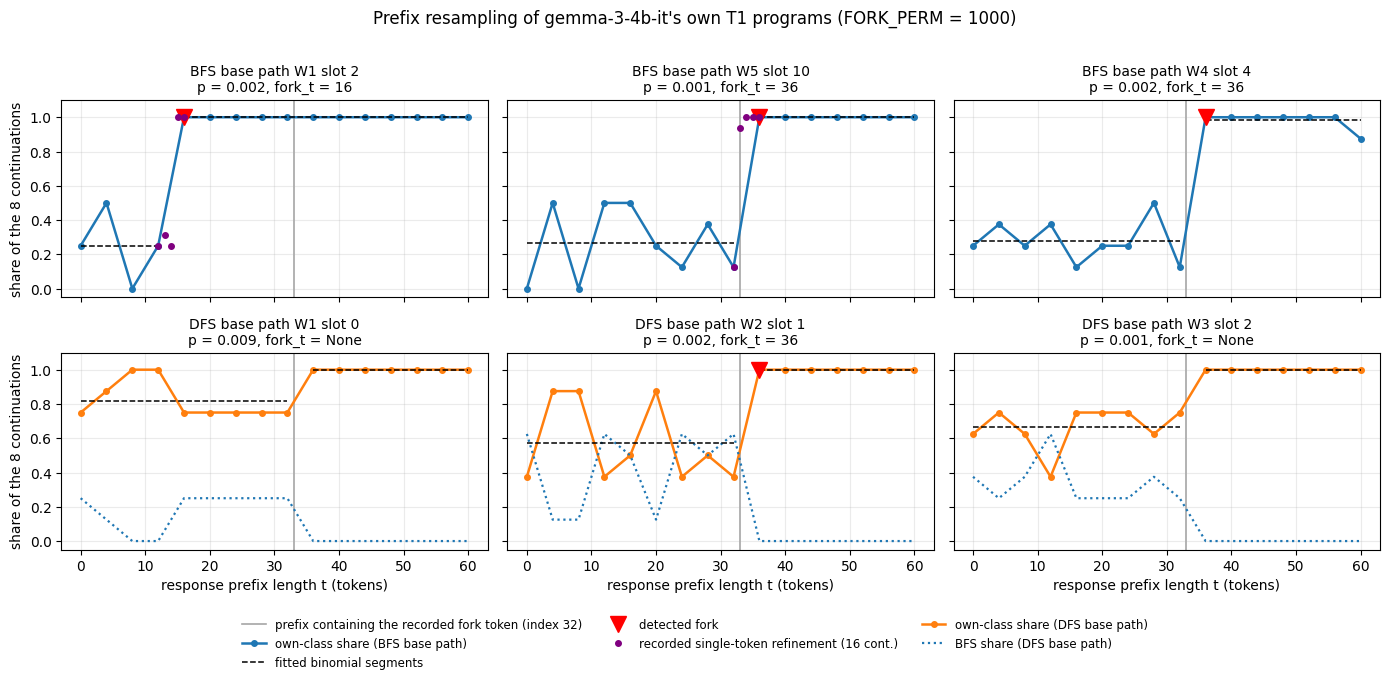

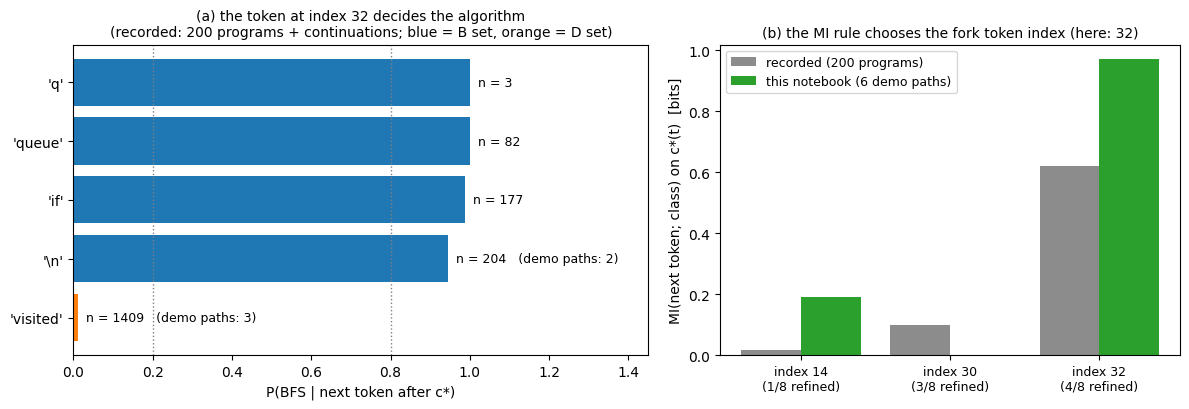

In [13]:
# ---- Figure 1: class of the continuations vs response prefix length, one panel per base path
COL = {"bfs": "tab:blue", "dfs": "tab:orange"}
ref = {r["row_id"]: r for r in REC["refined"]}
fork_len = REC["fork_token_index"] + 1          # shortest response prefix that contains the recorded fork token
fig, axes = plt.subplots(2, N_PATHS_PER_CLASS, figsize=(4.4 * N_PATHS_PER_CLASS + 0.8, 6.8), squeeze=False,
                         sharex=True, sharey=True)
for row, cls in enumerate(("bfs", "dfs")):
    pp = [p for p in per_path if p["label"] == cls]
    for col in range(N_PATHS_PER_CLASS):
        ax = axes[row, col]
        if col >= len(pp):
            ax.axis("off")
            continue
        p = pp[col]
        own_share = np.array(p["k_own"]) / np.array(p["n"])
        ax.axvline(fork_len, color="0.65", lw=1.2, zorder=0,
                   label=f"prefix containing the recorded fork token (index {REC['fork_token_index']})")
        ax.plot(p["t"], own_share, "o-", color=COL[cls], lw=1.8, ms=4, label=f"own-class share ({cls.upper()} base path)")
        if cls == "dfs":
            ax.plot(p["t"], p["p_bfs"], ":", color=COL["bfs"], lw=1.6, label="BFS share (DFS base path)")
        for s in p["cp"]["segments"]:
            ax.hlines(s["p"], p["t"][s["start_idx"]], p["t"][s["end_idx"] - 1], colors="k", linestyles="--", lw=1.1,
                      label="fitted binomial segments")
        if p["fork_t"] is not None:
            ax.plot(p["fork_t"], own_share[p["t"].index(p["fork_t"])], "v", color="red", ms=11, label="detected fork")
        if p["row_id"] in ref:
            s = ref[p["row_id"]]["series"]
            ax.plot([x["t"] for x in s], [x["p_own"] for x in s], ".", color="purple", ms=8,
                    label="recorded single-token refinement (16 cont.)")
        w_, slot_ = p["row_id"].split("|")[2], p["row_id"].split("|")[4]
        ax.set_title(f"{cls.upper()} base path {w_} slot {slot_}\np = {p['cp']['p_value']:.3f}, fork_t = {p['fork_t']}",
                     fontsize=10)
        ax.set_ylim(-0.05, 1.1)
        ax.grid(alpha=0.25)
        if row == 1:
            ax.set_xlabel("response prefix length t (tokens)")
        if col == 0:
            ax.set_ylabel("share of the 8 continuations")
handles = {}
for ax in axes.flat:
    for h, l in zip(*ax.get_legend_handles_labels()):
        handles.setdefault(l, h)
fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=3, fontsize=8.5, frameon=False)
fig.suptitle(f"Prefix resampling of gemma-3-4b-it's own T1 programs (FORK_PERM = {FORK_PERM})", fontsize=12)
fig.tight_layout(rect=(0, 0.1, 1, 0.97))
plt.show()

# ---- Figure 2: the fork token. (a) recorded next-token table after c*; (b) the MI rule over candidate fork indices
fig, (axa, axb) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
tt = sorted(REC["token_table"].values(), key=lambda v: v["p_bfs"])
cols = [COL["bfs"] if v["token"] in REC["B_tokens"] else COL["dfs"] if v["token"] in REC["D_tokens"] else "0.6" for v in tt]
axa.barh([repr(v["token"]) for v in tt], [v["p_bfs"] for v in tt], color=cols)
same_cstar = cstar == REC["cstar_ids"]          # the demo token table refers to the same position only then
for i, v in enumerate(tt):
    demo = next((d for t_, d in table.items() if tok_str.get(t_) == v["token"]), None) if same_cstar else None
    axa.text(min(v["p_bfs"], 1.0) + 0.02, i, f"n = {v['n']}" + (f"   (demo paths: {demo['n']})" if demo else ""),
             va="center", fontsize=9)
axa.set_xlim(0, 1.45)
axa.axvline(TOKEN_SET_HI, color="0.5", ls=":", lw=1)
axa.axvline(TOKEN_SET_LO, color="0.5", ls=":", lw=1)
axa.set_xlabel("P(BFS | next token after c*)")
axa.set_title(f"(a) the token at index {REC['fork_token_index']} decides the algorithm\n"
              "(recorded: 200 programs + continuations; blue = B set, orange = D set)", fontsize=10)
cand = sorted(REC["fork_index_rule"]["candidates"], key=int)
n_ref = sum(v["n_paths"] for v in REC["fork_index_rule"]["candidates"].values())
x = np.arange(len(cand))
axb.bar(x - 0.2, [REC["fork_index_rule"]["candidates"][c]["mi_bits"] for c in cand], 0.4, color="0.55",
        label="recorded (200 programs)")
if fork_rule.get("candidates"):
    axb.bar(x + 0.2, [fork_rule["candidates"].get(c, {}).get("mi_bits", 0.0) for c in cand], 0.4, color="tab:green",
            label=f"this notebook ({len(ids_all)} demo paths)")
axb.set_xticks(x, [f"index {c}\n({REC['fork_index_rule']['candidates'][c]['n_paths']}/{n_ref} refined)" for c in cand],
               fontsize=9)
axb.set_ylabel("MI(next token; class) on c*(t)  [bits]")
axb.set_title(f"(b) the MI rule chooses the fork token index (here: {tf})", fontsize=10)
axb.legend(fontsize=9)
fig.tight_layout()
plt.show()

## Takeaways

- **The algorithm is chosen at one early token, not gradually.**
  - On each BFS base path, the share of BFS continuations stays around the model's natural rate and then jumps to about 1.0 within one 4-token step. The jump comes at t = 36 on two of the demo paths and at t = 16 on W1 slot 2, which opens differently.
  - Every one of these changes beats the permutation null (p ≤ 0.002 here, ≤ 0.003 on all 12 BFS paths of the full run).
- **DFS is the default.** DFS base paths already have a high own-class share before the fork (segment means 0.57–0.82 here). So their rise usually stays below the 0.4 needed to call a fork: 1 of 12 in the full run, W2 slot 1 here, whose pre-fork share is unusually low.
- **The deciding token follows an opening with no algorithm-identifying code.**
  - The shared 32-token opening c\* contains nothing the labeller can classify; the partial labeller returns `None` on it, and also on c\* plus any of the fork tokens.
  - The next token then decides. Continuing with `visited` leads to DFS (P(BFS) = 0.011 over 1,409 cases in the full run). A blank line, `if`, `queue` or `q` lead to BFS. Code that identifies the algorithm appears only about 138 tokens later.
- **This is where the GPU stages intervene.** The residual-stream edits summarised in the introduction act at this position. There the plan can be pushed towards BFS, but only at a cost in correctness.